<a href="https://colab.research.google.com/github/tio22-png/Praktikum_PCVK_Hanggoro/blob/main/Modul2_PCVK_Hanggoro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Perbedaan cv2_imshow() dan plt.imshow() tanpa konversi warna

Jawaban: Hasilnya berbeda karena pustaka OpenCV (cv2) secara historis membaca dan menyimpan citra dalam urutan kanal warna BGR (Blue, Green, Red). Sebaliknya, Matplotlib (plt.imshow()) mengasumsikan bahwa array citra yang dimasukkan sudah berurutan RGB (Red, Green, Blue). Jika citra BGR langsung dimasukkan ke plt.imshow() tanpa dikonversi, kanal Merah dan Birunya akan tertukar, sehingga gambar terlihat kebiruan/kemerahan yang tidak wajar.

In [4]:
import cv2
import matplotlib.pyplot as plt

# Buka gambar (pastikan file '64e59deb79bfb.jpg' sudah diupload ke Colab)
img_bgr = cv2.imread('64e59deb79bfb.jpg')

print("Membuktikan urutan BGR (B, G, R) pada pixel [0,0]:")
print("Nilai pixel dari cv2.imread :", img_bgr[0,0])

# Jika dikonversi ke RGB, urutan array angka pertama dan ketiga akan bertukar
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
print("Nilai pixel setelah di RGB-kan:", img_rgb[0,0])

Membuktikan urutan BGR (B, G, R) pada pixel [0,0]:
Nilai pixel dari cv2.imread : [237 230 215]
Nilai pixel setelah di RGB-kan: [215 230 237]


2. Perbandingan kanvas hitam int16 dan int32
Jawaban: Tampilan visual kedua kanvas tidak berbeda (keduanya tampak hitam pekat) karena nilai intensitas 0 pada kedua tipe data tersebut sama-sama merepresentasikan warna hitam. Namun, ukuran memori (nbytes) keduanya berbeda. Tipe data int16 (2 byte) mengonsumsi memori setengah lebih kecil dibandingkan int32 (4 byte) per pikselnya. Rentang nilai (min() dan max()) juga berbeda; int16 menampung dari –32.768 hingga 32.767, sedangkan int32 dari –2.147.483.648 hingga 2.147.483.647. Tipe int32 wajib digunakan saat menggambar larik titik polyline (cv2.polylines) di OpenCV.

In [5]:
import numpy as np

kanvas_16 = np.zeros((100, 100, 3), dtype=np.int16)
kanvas_32 = np.zeros((100, 100, 3), dtype=np.int32)

print("Kanvas int16: dtype=", kanvas_16.dtype, "| min=", np.min(kanvas_16), "| max (tipe)=", np.iinfo(kanvas_16.dtype).max, "| bytes=", kanvas_16.nbytes)
print("Kanvas int32: dtype=", kanvas_32.dtype, "| min=", np.min(kanvas_32), "| max (tipe)=", np.iinfo(kanvas_32.dtype).max, "| bytes=", kanvas_32.nbytes)

Kanvas int16: dtype= int16 | min= 0 | max (tipe)= 32767 | bytes= 60000
Kanvas int32: dtype= int32 | min= 0 | max (tipe)= 2147483647 | bytes= 120000


3. Kegunaan cv2_imshow dari google.colab.patches
Jawaban: Fungsi bawaan cv2.imshow() milik OpenCV membutuhkan eksekusi jendela antarmuka GUI (Graphical User Interface) pada sistem operasi lokal untuk menampilkan gambar. Karena Google Colab berbasis browser web dan berjalan di peladen awan (cloud), pemanggilan GUI lokal tidak dimungkinkan dan akan menyebabkan error sistem. Pustaka patch ini disediakan agar output citra dialihkan untuk dirender langsung sebagai output sel HTML/gambar di dalam browser

4. skimage.io.imread() vs cv2.cvtColor()
Jawaban: Fungsi pembaca citra skimage.io.imread() secara native (bawaan) langsung membaca dan menyimpan array citra dalam format urutan RGB. Jika kita memaksakan fungsi cv2.cvtColor(img, cv2.COLOR_BGR2RGB) terhadap citra yang dihasilkan oleh skimage, kita justru secara keliru menukar kembali susunan yang sudah benar (RGB) menjadi BGR, sehingga warnanya menjadi terbalik dan salah.

In [6]:
from skimage import io
import cv2

img_ski = io.imread('64e59deb79bfb.jpg') # Otomatis RGB
img_salah = cv2.cvtColor(img_ski, cv2.COLOR_BGR2RGB) # RGB ditukar jadi BGR secara keliru

print("Pixel [0,0] dari skimage (RGB Benar):", img_ski[0,0])
print("Pixel [0,0] setelah dipaksa cvtColor (Tertukar):", img_salah[0,0])

Pixel [0,0] dari skimage (RGB Benar): [215 230 237]
Pixel [0,0] setelah dipaksa cvtColor (Tertukar): [237 230 215]


5. figsize vs img.shape
Jawaban: Tidak, nilai img.shape tidak ikut berubah sama sekali. Parameter figsize pada plt.figure() hanya berfungsi mengatur ukuran kanvas visual/tampilan (dalam satuan inci) pada antarmuka layar saja. Ini berbeda dengan mengubah ukuran citra (misalnya memakai cv2.resize()), yang secara nyata menambah atau mengurangi jumlah piksel data di dalam memori komputer dan secara permanen mengubah nilai matriks citranya.

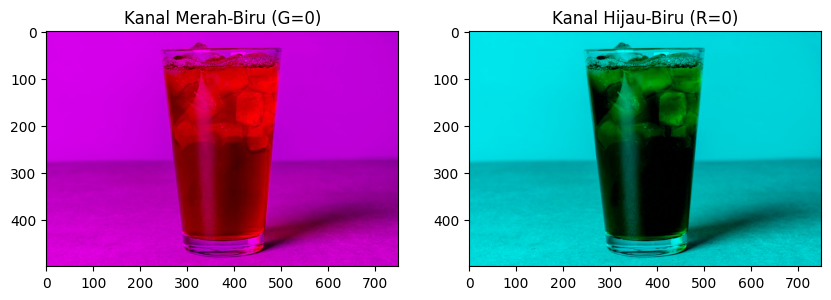

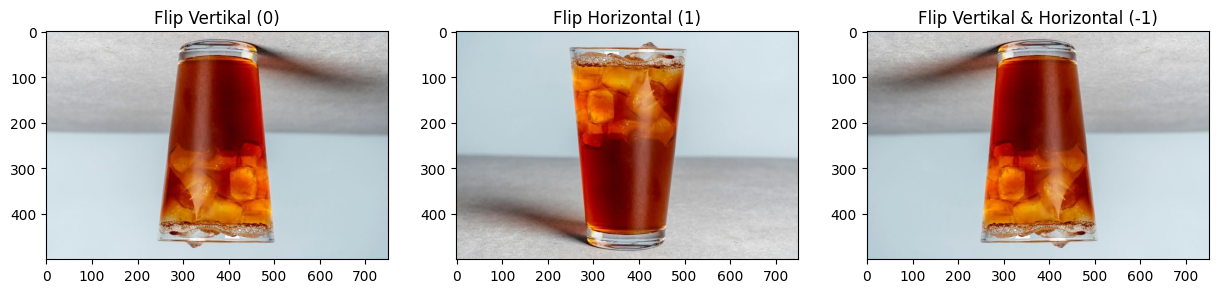

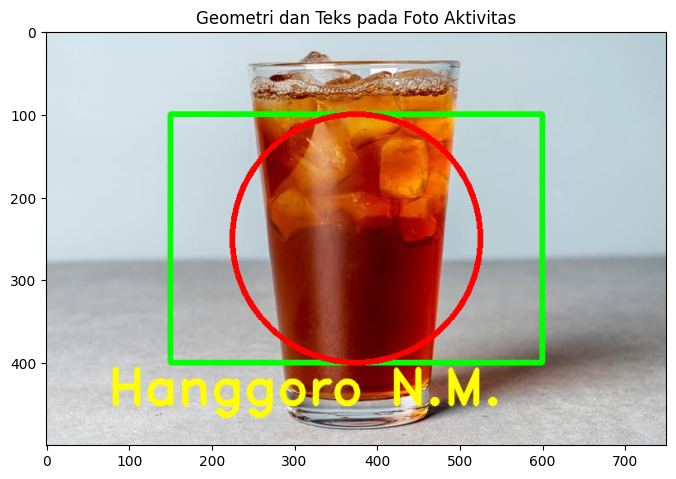

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra dan konversi ke RGB
img = cv2.imread('64e59deb79bfb.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Tugas 1: Kanal Merah-Biru dan Hijau-Biru
# Salin citra asli (pengirisan pada NumPy menghasilkan view, gunakan copy agar aman)
img_rb = img.copy()
img_rb[:, :, 1] = 0 # Kanal indeks 1 (Hijau) dinolkan

img_gb = img.copy()
img_gb[:, :, 0] = 0 # Kanal indeks 0 (Merah) dinolkan

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rb)
plt.title('Kanal Merah-Biru (G=0)')

plt.subplot(1, 2, 2)
plt.imshow(img_gb)
plt.title('Kanal Hijau-Biru (R=0)')
plt.show()


# Tugas 2: Tiga Bentuk Pencerminan (Flip)
# Pencerminan: 0 (Vertikal), 1 (Horizontal), -1 (Keduanya)
flip_vertikal = cv2.flip(img, 0)
flip_horizontal = cv2.flip(img, 1)
flip_keduanya = cv2.flip(img, -1)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(flip_vertikal)
plt.title('Flip Vertikal (0)')

plt.subplot(1, 3, 2)
plt.imshow(flip_horizontal)
plt.title('Flip Horizontal (1)')

plt.subplot(1, 3, 3)
plt.imshow(flip_keduanya)
plt.title('Flip Vertikal & Horizontal (-1)')
plt.show()


# Tugas 3: Geometri dan Teks Kustom
img_geo = img.copy()
h, w = img_geo.shape[:2] # Membaca resolusi dengan aman[cite: 2]

# Menggambar Rectangle & Lingkaran adaptif di area tengah badan
cv2.rectangle(img_geo, (int(w*0.2), int(h*0.2)), (int(w*0.8), int(h*0.8)), (0, 255, 0), 5)
cv2.circle(img_geo, (int(w*0.5), int(h*0.5)), int(w*0.2), (255, 0, 0), 5)

# Menambahkan nama dengan font, skala, dan warna kustom[cite: 2]
font = cv2.FONT_HERSHEY_DUPLEX
# Tepi halus dengan lineType=cv2.LINE_AA[cite: 2]
cv2.putText(img_geo, "Hanggoro N.M.", (int(w*0.1), int(h*0.9)), font, 2, (255, 255, 0), 3, cv2.LINE_AA)

plt.figure(figsize=(8, 8))
plt.imshow(img_geo)
plt.title("Geometri dan Teks pada Foto Aktivitas")
plt.show()

Tugas Praktikum - Analisa
Tugas ini meminta perumusan pertanyaan berbasis data citra.
Pertanyaan: Apakah melakukan kompresi pengubahan ukuran (downscaling) pada citra mengubah nilai rata-rata intensitas piksel secara signifikan?
Rancangan Program: Kita akan menghitung np.mean() (nilai rata-rata piksel) dari foto asli, lalu membandingkannya dengan nilai rata-rata foto yang sudah di-resize ukurannya menjadi sangat kecil menggunakan metode interpolasi INTER_AREA (yang direkomendasikan untuk downscaling)[cite: 2].

In [8]:
# TUGAS ANALISA
import cv2
import numpy as np

img_asli = cv2.imread('64e59deb79bfb.jpg')
img_asli = cv2.cvtColor(img_asli, cv2.COLOR_BGR2RGB)

# Resize menjadi 10% dari ukuran asli menggunakan INTER_AREA[cite: 2]
h, w = img_asli.shape[:2]
img_kecil = cv2.resize(img_asli, (int(w*0.1), int(h*0.1)), interpolation=cv2.INTER_AREA)

# Hitung Rata-rata
mean_asli = np.mean(img_asli)
mean_kecil = np.mean(img_kecil)

print(f"Rata-rata intensitas piksel foto asli  : {mean_asli:.2f}")
print(f"Rata-rata intensitas piksel foto kecil : {mean_kecil:.2f}")

# Kesimpulan akan muncul otomatis di output saat di print:
print("\nKesimpulan: Mengubah ukuran piksel (resize) akan memodifikasi/menghilangkan beberapa data asli.")
print("Nilai rata-rata piksel (mean intensity) akan bergeser, meskipun perubahannya biasanya kecil.")

Rata-rata intensitas piksel foto asli  : 169.00
Rata-rata intensitas piksel foto kecil : 169.00

Kesimpulan: Mengubah ukuran piksel (resize) akan memodifikasi/menghilangkan beberapa data asli.
Nilai rata-rata piksel (mean intensity) akan bergeser, meskipun perubahannya biasanya kecil.


Tugas Praktikum - Aplikasi (Adaptif)
Pada tugas studi kasus ini, koordinat ukuran, garis, dan font harus dihitung secara matematika (dinamis/adaptif) dari dimensi gambar[cite: 2], bukan ditulis manual dengan angka statis.

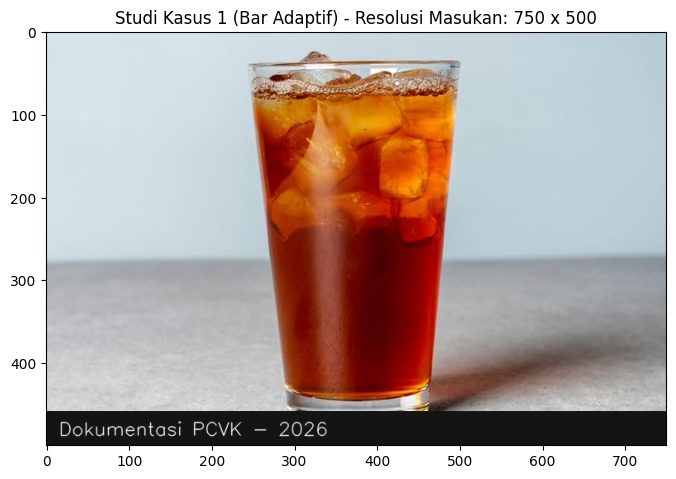

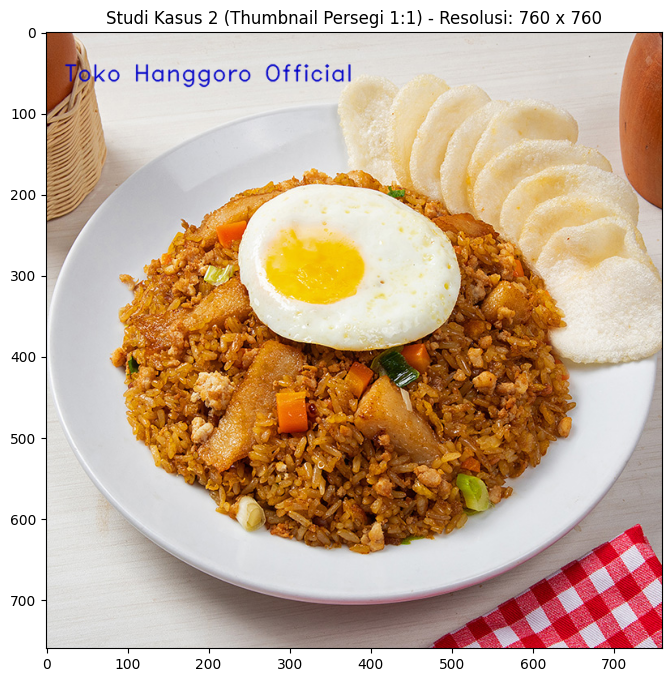

In [9]:

# Studi Kasus 1: Bar Identitas Adaptif
img_kasus1 = cv2.imread('64e59deb79bfb.jpg')
img_kasus1 = cv2.cvtColor(img_kasus1, cv2.COLOR_BGR2RGB)
h1, w1 = img_kasus1.shape[:2]

# Menghitung proporsi secara adaptif berdasarkan ukuran asli[cite: 2]
tinggi_bar = int(h1 / 12)  # Tinggi bar selalu 1/12 dari tinggi gambar
skala_font = w1 / 1000     # Font menyesuaikan kelebaran gambar
ketebalan = max(1, int(w1 / 500))

# Menggambar bar hitam di bagian bawah (-1 artinya blok padat/terisi penuh)[cite: 2]
cv2.rectangle(img_kasus1, (0, h1 - tinggi_bar), (w1, h1), (20, 20, 20), -1)

# Menggambar teks (Dokumentasi PCVK - 2026) rata kiri di dalam bar
cv2.putText(img_kasus1, "Dokumentasi PCVK - 2026", (int(w1*0.02), int(h1 - tinggi_bar/3.5)),
            cv2.FONT_HERSHEY_SIMPLEX, skala_font, (255, 255, 255), ketebalan, cv2.LINE_AA)

plt.figure(figsize=(8,8))
plt.imshow(img_kasus1)
plt.title(f"Studi Kasus 1 (Bar Adaptif) - Resolusi Masukan: {w1} x {h1}")
plt.show()

# Studi Kasus 2: Thumbnail 1:1 Persegi (Padding)

img_kasus2 = cv2.imread('Nasi-Goreng-Spesial.jpg')
img_kasus2 = cv2.cvtColor(img_kasus2, cv2.COLOR_BGR2RGB)
h2, w2 = img_kasus2.shape[:2]

# Mencari sisi terpanjang untuk dijadikan ukuran bingkai persegi
sisi_max = max(h2, w2)

# Membuat kanvas kosong berbentuk persegi 1:1, latar warna putih (255) dengan uint8[cite: 2]
kanvas_persegi = np.full((sisi_max, sisi_max, 3), 255, dtype=np.uint8)

# Menghitung titik tengah kordinat (offset) agar gambar jatuh persis di tengah
y_offset = (sisi_max - h2) // 2
x_offset = (sisi_max - w2) // 2

# Memasukkan matriks citra asli ke koordinat spesifik kanvas persegi[cite: 2]
kanvas_persegi[y_offset : y_offset + h2, x_offset : x_offset + w2] = img_kasus2

# Menambahkan logo teks nama toko secara adaptif di pojok kiri atas (di atas gambar jika landscape)
skala_font_logo = sisi_max / 800
tebal_logo = max(1, int(sisi_max / 400))
cv2.putText(kanvas_persegi, "Toko Hanggoro Official", (int(sisi_max*0.03), int(sisi_max*0.08)),
            cv2.FONT_HERSHEY_DUPLEX, skala_font_logo, (0, 0, 200), tebal_logo, cv2.LINE_AA)

plt.figure(figsize=(8,8))
plt.imshow(kanvas_persegi)
plt.title(f"Studi Kasus 2 (Thumbnail Persegi 1:1) - Resolusi: {sisi_max} x {sisi_max}")
plt.show()